In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

import re
import copy

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
train_df = pd.read_csv("/content/drive/My Drive/Book_Genres/bgc_train.csv")
test_df = pd.read_csv("/content/drive/My Drive/Book_Genres/bgc_test.csv")
val_df = pd.read_csv("/content/drive/My Drive/Book_Genres/bgc_dev.csv")

In [5]:
train_df.head()

,Number,Title,Body,Topics
0,1,The New York Times Daily Crossword Puzzles: Th...,Monday’s Crosswords Do with EaseTuesday’s Cros...,Nonfiction>Games
1,2,Creatures of the Night (Second Edition),Two of literary comics modern masters present ...,Fiction>Graphic Novels & Manga
2,3,Cornelia and the Audacious Escapades of the So...,Eleven-year-old Cornelia is the daughter of tw...,Children’s Books>Children’s Middle Grade Books
3,4,The Alchemist's Daughter,"During the English Age of Reason, a woman cloi...",Fiction>Historical Fiction
4,5,Dangerous Boy,A modern-day retelling of The Strange Case of ...,Teen & Young Adult>Teen & Young Adult Mystery ...


In [7]:
test_df.head()

,Number,Title,Body,Labels
0,1,Teenage Mutant Ninja Turtles: The Box Set Volu...,TMNT co-creator Kevin Eastman and writer Tom W...,Fiction>Graphic Novels & Manga
1,2,Betty & Veronica: Fairy Tales,Take a magical trip down Storybook Lane with t...,Children’s Books>Children’s Middle Grade Books
2,3,Friends & Fauxs,"Tracie Howard is back with all of the Gucci, g...",Fiction>Women’s Fiction
3,4,Anti-Education,"AN NYRB Classics OriginalIn 1869, at the age o...",Nonfiction>Religion & Philosophy>Philosophy
4,5,Fallout,A first-class letter–containing a single sheet...,Fiction>Mystery & Suspense>Espionage Mysteries...


In [8]:
val_df.head()

,Number,Title,Body,Topics
0,1,Trailsman #267: California Casualties,Fargo tangles with a terrible town tyrant!Skye...,Fiction>Western Fiction
1,2,Valentine Be Mine,"Chocolate, flowers, poems, gifts—all of these ...",Children’s Books
2,3,To Mervas,To Mervas is a turbulent journey through the w...,Fiction>Literary Fiction
3,4,Smart Money Moves for African-Americans,The host of PBS’s The Color of Money presents ...,"Nonfiction>Self-Improvement>Personal Growth,No..."
4,5,Another Chance to Get It Right (3rd ed.) (boo...,When Another Chance to Get it Right debuted on...,Nonfiction>Parenting


In [9]:
train_df.shape, test_df.shape, val_df.shape

((58715, 4), (18394, 4), (14785, 4))

In [10]:
train_df.shape[0] + test_df.shape[0] + val_df.shape[0]

91894

In [11]:
train_df.head(10)

,Number,Title,Body,Topics
0,1,The New York Times Daily Crossword Puzzles: Th...,Monday’s Crosswords Do with EaseTuesday’s Cros...,Nonfiction>Games
1,2,Creatures of the Night (Second Edition),Two of literary comics modern masters present ...,Fiction>Graphic Novels & Manga
2,3,Cornelia and the Audacious Escapades of the So...,Eleven-year-old Cornelia is the daughter of tw...,Children’s Books>Children’s Middle Grade Books
3,4,The Alchemist's Daughter,"During the English Age of Reason, a woman cloi...",Fiction>Historical Fiction
4,5,Dangerous Boy,A modern-day retelling of The Strange Case of ...,Teen & Young Adult>Teen & Young Adult Mystery ...
5,6,Mystery Mother (Replica #8),"Amy knows Nancy isn’t her birth mother, but sh...",Children’s Books>Children’s Middle Grade Books
6,7,The Woman Who Wouldn't Die,The long-awaited follow-up to 2011’s Slash &am...,Fiction>Mystery & Suspense>Crime Mysteries
7,8,The EC Archives: Two-Fisted Tales Volume 3,Before Two-Fisted Tales burst onto the scene i...,Fiction>Graphic Novels & Manga
8,9,The Complete Idiot's Guide to Intermediate Spa...,This revised edition offers expanded coverage ...,"Nonfiction>Reference>Language,Nonfiction>Refer..."
9,10,Comic Sans Murder,"Clare Henry’s snowy Star City, Utah, oasis tur...",Fiction>Mystery & Suspense>Cozy Mysteries


# Top Level Genre Classification :

<hr />

# Data Preprocessing :

In [6]:
test_df = test_df.rename(columns={'Labels' : 'Topics'})

In [7]:
df = pd.concat([train_df, test_df, val_df], ignore_index=True)
df.head()

,Number,Title,Body,Topics
0,1,The New York Times Daily Crossword Puzzles: Th...,Monday’s Crosswords Do with EaseTuesday’s Cros...,Nonfiction>Games
1,2,Creatures of the Night (Second Edition),Two of literary comics modern masters present ...,Fiction>Graphic Novels & Manga
2,3,Cornelia and the Audacious Escapades of the So...,Eleven-year-old Cornelia is the daughter of tw...,Children’s Books>Children’s Middle Grade Books
3,4,The Alchemist's Daughter,"During the English Age of Reason, a woman cloi...",Fiction>Historical Fiction
4,5,Dangerous Boy,A modern-day retelling of The Strange Case of ...,Teen & Young Adult>Teen & Young Adult Mystery ...


In [8]:
df.isna().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["Top_Level_Topics"] = df["Topics"].apply(lambda x: x.split(">")[0])
df.head()

,Number,Title,Body,Topics,Top_Level_Topics
0,1,The New York Times Daily Crossword Puzzles: Th...,Monday’s Crosswords Do with EaseTuesday’s Cros...,Nonfiction>Games,Nonfiction
1,2,Creatures of the Night (Second Edition),Two of literary comics modern masters present ...,Fiction>Graphic Novels & Manga,Fiction
2,3,Cornelia and the Audacious Escapades of the So...,Eleven-year-old Cornelia is the daughter of tw...,Children’s Books>Children’s Middle Grade Books,Children’s Books
3,4,The Alchemist's Daughter,"During the English Age of Reason, a woman cloi...",Fiction>Historical Fiction,Fiction
4,5,Dangerous Boy,A modern-day retelling of The Strange Case of ...,Teen & Young Adult>Teen & Young Adult Mystery ...,Teen & Young Adult


In [11]:
df["Top_Level_Topics"].value_counts()

,count
Top_Level_Topics,
Nonfiction,33129
Fiction,31540
Children’s Books,19520
Teen & Young Adult,3661
Classics,1685
Poetry,504
"Humor,Nonfiction",485
Humor,427
"Poetry,Classics",288


In [12]:
df["Top_Level_Topics"] = df["Top_Level_Topics"].str.split(",")

In [13]:
df["Top_Level_Topics"].head()

,Top_Level_Topics
0,[Nonfiction]
1,[Fiction]
2,[Children’s Books]
3,[Fiction]
4,[Teen & Young Adult]


In [14]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()

y = mlb.fit_transform(df["Top_Level_Topics"])

In [15]:
y[:5]

array([[0, 0, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0, 0, 0, 0],
       [1, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1]])

In [16]:
label_counts = pd.Series(
    y.sum(axis=0),
    index=mlb.classes_
).sort_values(ascending=False)

print(label_counts)

Nonfiction            33835
Fiction               31917
Children’s Books      19547
Teen & Young Adult     3686
Classics               2188
Humor                  1124
Poetry                  911
Crafts                  142
dtype: int64


- nbr of **crafts** labels is **sooo small**, i'll **delete** it
- later : i found also that there isn't **crafts** label in **training** data ! makes it more **justified** to **delete** it

In [17]:
df["Top_Level_Topics"] = df["Top_Level_Topics"].apply(
    lambda labels: [label for label in labels if label != "Crafts"]
)

y = mlb.fit_transform(df["Top_Level_Topics"])

y[:5]

array([[0, 0, 0, 0, 1, 0, 0],
       [0, 0, 1, 0, 0, 0, 0],
       [1, 0, 0, 0, 0, 0, 0],
       [0, 0, 1, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1]])

In [18]:
label_counts = pd.Series(
    y.sum(axis=0),
    index=mlb.classes_
).sort_values(ascending=False)

print(label_counts)

Nonfiction            33835
Fiction               31917
Children’s Books      19547
Teen & Young Adult     3686
Classics               2188
Humor                  1124
Poetry                  911
dtype: int64


In [19]:
df["Top_Level_Topics"] = list(y)

In [20]:
df["Top_Level_Topics"].head()

,Top_Level_Topics
0,"[0, 0, 0, 0, 1, 0, 0]"
1,"[0, 0, 1, 0, 0, 0, 0]"
2,"[1, 0, 0, 0, 0, 0, 0]"
3,"[0, 0, 1, 0, 0, 0, 0]"
4,"[0, 0, 0, 0, 0, 0, 1]"


# EDA :

In [21]:
df["tokens"] = df["Body"].str.split()
df.head(10)

,Number,Title,Body,Topics,Top_Level_Topics,tokens
0,1,The New York Times Daily Crossword Puzzles: Th...,Monday’s Crosswords Do with EaseTuesday’s Cros...,Nonfiction>Games,"[0, 0, 0, 0, 1, 0, 0]","[Monday’s, Crosswords, Do, with, EaseTuesday’s..."
1,2,Creatures of the Night (Second Edition),Two of literary comics modern masters present ...,Fiction>Graphic Novels & Manga,"[0, 0, 1, 0, 0, 0, 0]","[Two, of, literary, comics, modern, masters, p..."
2,3,Cornelia and the Audacious Escapades of the So...,Eleven-year-old Cornelia is the daughter of tw...,Children’s Books>Children’s Middle Grade Books,"[1, 0, 0, 0, 0, 0, 0]","[Eleven-year-old, Cornelia, is, the, daughter,..."
3,4,The Alchemist's Daughter,"During the English Age of Reason, a woman cloi...",Fiction>Historical Fiction,"[0, 0, 1, 0, 0, 0, 0]","[During, the, English, Age, of, Reason,, a, wo..."
4,5,Dangerous Boy,A modern-day retelling of The Strange Case of ...,Teen & Young Adult>Teen & Young Adult Mystery ...,"[0, 0, 0, 0, 0, 0, 1]","[A, modern-day, retelling, of, The, Strange, C..."
5,6,Mystery Mother (Replica #8),"Amy knows Nancy isn’t her birth mother, but sh...",Children’s Books>Children’s Middle Grade Books,"[1, 0, 0, 0, 0, 0, 0]","[Amy, knows, Nancy, isn’t, her, birth, mother,..."
6,7,The Woman Who Wouldn't Die,The long-awaited follow-up to 2011’s Slash &am...,Fiction>Mystery & Suspense>Crime Mysteries,"[0, 0, 1, 0, 0, 0, 0]","[The, long-awaited, follow-up, to, 2011’s, Sla..."
7,8,The EC Archives: Two-Fisted Tales Volume 3,Before Two-Fisted Tales burst onto the scene i...,Fiction>Graphic Novels & Manga,"[0, 0, 1, 0, 0, 0, 0]","[Before, Two-Fisted, Tales, burst, onto, the, ..."
8,9,The Complete Idiot's Guide to Intermediate Spa...,This revised edition offers expanded coverage ...,"Nonfiction>Reference>Language,Nonfiction>Refer...","[0, 0, 0, 0, 1, 0, 0]","[This, revised, edition, offers, expanded, cov..."
9,10,Comic Sans Murder,"Clare Henry’s snowy Star City, Utah, oasis tur...",Fiction>Mystery & Suspense>Cozy Mysteries,"[0, 0, 1, 0, 0, 0, 0]","[Clare, Henry’s, snowy, Star, City,, Utah,, oa..."


In [22]:
df["nbr_tokens"] = df["tokens"].str.len()
df.head()

,Number,Title,Body,Topics,Top_Level_Topics,tokens,nbr_tokens
0,1,The New York Times Daily Crossword Puzzles: Th...,Monday’s Crosswords Do with EaseTuesday’s Cros...,Nonfiction>Games,"[0, 0, 0, 0, 1, 0, 0]","[Monday’s, Crosswords, Do, with, EaseTuesday’s...",127
1,2,Creatures of the Night (Second Edition),Two of literary comics modern masters present ...,Fiction>Graphic Novels & Manga,"[0, 0, 1, 0, 0, 0, 0]","[Two, of, literary, comics, modern, masters, p...",96
2,3,Cornelia and the Audacious Escapades of the So...,Eleven-year-old Cornelia is the daughter of tw...,Children’s Books>Children’s Middle Grade Books,"[1, 0, 0, 0, 0, 0, 0]","[Eleven-year-old, Cornelia, is, the, daughter,...",111
3,4,The Alchemist's Daughter,"During the English Age of Reason, a woman cloi...",Fiction>Historical Fiction,"[0, 0, 1, 0, 0, 0, 0]","[During, the, English, Age, of, Reason,, a, wo...",114
4,5,Dangerous Boy,A modern-day retelling of The Strange Case of ...,Teen & Young Adult>Teen & Young Adult Mystery ...,"[0, 0, 0, 0, 0, 0, 1]","[A, modern-day, retelling, of, The, Strange, C...",148


<Axes: >

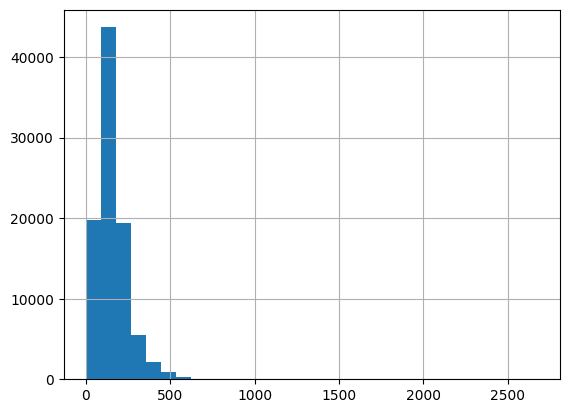

In [23]:
df["nbr_tokens"].hist(bins=30)

In [24]:
df["nbr_tokens"].describe()

,nbr_tokens
count,91894.000000
mean,156.962479
std,89.621293
min,1.000000
25%,97.000000
50%,142.000000
75%,195.000000
max,2675.000000


In [25]:
print("mean", df["nbr_tokens"].mean())
print("median", df["nbr_tokens"].median())

mean 156.962478507846
median 142.0


In [26]:
df[df["nbr_tokens"] > 500].shape[0]

657

# Data Splitting :

In [27]:
# train_df, test_df, val_df

### Tokenization :

In [28]:
train_df["tokens"] = train_df["Body"].str.split()
test_df["tokens"] = test_df["Body"].str.split()
val_df["tokens"] = val_df["Body"].str.split()

### Extracting top level topic :

In [29]:
train_df["Top_Level_Topics"] = train_df["Topics"].apply(lambda x: x.split(">")[0]).str.split(",")
test_df["Top_Level_Topics"] = test_df["Topics"].apply(lambda x: x.split(">")[0]).str.split(",")
val_df["Top_Level_Topics"] = val_df["Topics"].apply(lambda x: x.split(">")[0]).str.split(",")

In [30]:
val_df["Top_Level_Topics"].value_counts()

,count
Top_Level_Topics,
[Nonfiction],5258
[Fiction],4984
[Children’s Books],3122
[Teen & Young Adult],590
[Classics],377
"[Crafts, Nonfiction]",137
"[Poetry, Classics]",87
[Poetry],81
[Humor],68


In [31]:
"Crafts" in ["Crafts", "Nonfiction"]

True

In [32]:
val_df[
	val_df["Top_Level_Topics"].apply(
		lambda labels: "Crafts" in labels
	)
].shape[0]

142

In [33]:
val_df["Top_Level_Topics"] = val_df["Top_Level_Topics"].apply(
	lambda labels: [label for label in labels if label != "Crafts"]
)

In [34]:
val_df[
	val_df["Top_Level_Topics"].apply(
		lambda labels: "Crafts" in labels
	)
].shape[0]

0

### Label encoding :

In [35]:
y_train = mlb.fit_transform(train_df["Top_Level_Topics"])
y_test = mlb.transform(test_df["Top_Level_Topics"])
y_val = mlb.transform(val_df["Top_Level_Topics"])

In [36]:
labels = mlb.classes_
labels

array(['Children’s Books', 'Classics', 'Fiction', 'Humor', 'Nonfiction',
       'Poetry', 'Teen & Young Adult'], dtype=object)

In [37]:
train_df["Top_Level_Topics"] = list(y_train)
test_df["Top_Level_Topics"] = list(y_test)
val_df["Top_Level_Topics"] = list(y_val)

### Vocab (Word_idx) :
- **vocabulary** is created using only **training data** !

In [38]:
from collections import Counter

word_counts = Counter()

for tokens in train_df["tokens"]:
	word_counts.update(tokens)

In [39]:
most_common_words = word_counts.most_common(50_000)
len(most_common_words)

50000

In [40]:
most_common_words[:5]

[('the', 473099),
 ('and', 346644),
 ('of', 314815),
 ('a', 233916),
 ('to', 232819)]

In [41]:
# all_tokens = [
#   token for tokens in train_df["tokens"]
#   for token in tokens
# ]

# print(len(all_tokens))

# all_tokens = list(dict.fromkeys(all_tokens))

# print(len(all_tokens))

all_tokens = [
  token for (token, frq) in most_common_words
]

print(len(all_tokens))

50000


In [42]:
word_idx = {
  "<PAD>" : 0,
  "<UNK>" : 1
}

for token in all_tokens:
  word_idx[token] = len(word_idx)

for key, value in list(word_idx.items())[:5]:
    print(f"{key} : {value}")

<PAD> : 0
<UNK> : 1
the : 2
and : 3
of : 4


### Encoding :

In [43]:
train_df["encoded_tokens"] = train_df["tokens"].apply(
  lambda tokens : [word_idx.get(token, word_idx["<UNK>"]) for token in tokens]
)
test_df["encoded_tokens"] = test_df["tokens"].apply(
  lambda tokens : [word_idx.get(token, word_idx["<UNK>"]) for token in tokens]
)
val_df["encoded_tokens"] = val_df["tokens"].apply(
  lambda tokens : [word_idx.get(token, word_idx["<UNK>"]) for token in tokens]
)

In [44]:
train_df["encoded_tokens"].head()

,encoded_tokens
0,"[1, 39871, 1242, 10, 1, 39871, 674, 5, 1, 3987..."
1,"[1207, 4, 386, 1830, 227, 2638, 698, 5, 1731, ..."
2,"[22167, 28229, 8, 2, 570, 4, 86, 6685, 1, 1775..."
3,"[2639, 2, 499, 2239, 4, 44968, 5, 150, 18059, ..."
4,"[52, 2999, 3884, 4, 16, 7465, 8775, 4, 281, 29..."


### Padding :

In [45]:
max_len = 500

def collate_fn_cnn(batch):
	body, topic = zip(*batch)

	body = [torch.tensor(b, dtype=torch.long) for b in body]

	topic = torch.tensor(topic, dtype=torch.float32)

	body = [b[:max_len] for b in body]

	body = pad_sequence(
		body,
		padding_value = word_idx["<PAD>"],
		batch_first = True
	)

	return body, topic

# BGC Class :

In [46]:
class BGCDataset(Dataset):
	def __init__(self, body, topic):
		super().__init__()
		self.body = body
		self.topic = topic

	def __len__(self):
		return self.body.shape[0]

	def __getitem__(self, idx):
		return self.body.iloc[idx], self.topic.iloc[idx]

### Dataset & Dataloader :

In [47]:
train_data = BGCDataset(train_df["encoded_tokens"], train_df["Top_Level_Topics"])
val_data = BGCDataset(val_df["encoded_tokens"], val_df["Top_Level_Topics"])
test_data = BGCDataset(test_df["encoded_tokens"], test_df["Top_Level_Topics"])

train_loader_cnn = DataLoader(train_data, batch_size=128, shuffle=True, collate_fn=collate_fn_cnn)
val_loader_cnn = DataLoader(val_data, batch_size=128, shuffle=True, collate_fn=collate_fn_cnn)
test_loader_cnn = DataLoader(test_data, batch_size=128, shuffle=True, collate_fn=collate_fn_cnn)

# CNN Model :

In [54]:
class CnnModel(nn.Module):
	def __init__(self, vocab_size, embedding_dim, num_classes):
		super().__init__()
		self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=word_idx["<PAD>"])

		self.conv2 = nn.Conv1d(embedding_dim, embedding_dim, kernel_size=2, stride=1, padding=1)
		self.conv3 = nn.Conv1d(embedding_dim, embedding_dim, kernel_size=3, stride=1, padding=1)
		self.conv4 = nn.Conv1d(embedding_dim, embedding_dim, kernel_size=4, stride=1, padding=2)

		self.dropout = nn.Dropout(0.3)

		self.fc = nn.Linear(embedding_dim * 3, num_classes)

	def forward(self, x):  # (batch_size, sequence_length)
		x = self.embedding(x) # (batch_size, sequence_length, embedding_dim)
		x = x.permute(0, 2, 1) # (batch_size, embedding_dim, sequence_length)
		
		x2 = F.relu(self.conv2(x))
		x3 = F.relu(self.conv3(x))
		x4 = F.relu(self.conv4(x))

		p2 = F.max_pool1d(x2, x2.shape[2]).squeeze(2) # (batch_size, embedding_dim)
		p3 = F.max_pool1d(x3, x3.shape[2]).squeeze(2) # (batch_size, embedding_dim)
		p4 = F.max_pool1d(x4, x4.shape[2]).squeeze(2) # (batch_size, embedding_dim)

		x = torch.cat([p2, p3, p4], dim=1)
		x = self.dropout(x)
		out = self.fc(x)
		return out

### training :

In [57]:
device = torch.device("cuda")

In [58]:
labels

array(['Children’s Books', 'Classics', 'Fiction', 'Humor', 'Nonfiction',
       'Poetry', 'Teen & Young Adult'], dtype=object)

In [59]:
vocab_size = len(word_idx)
embedding_dim = 100
num_classes = len(labels)

In [60]:
positive = train_df["Top_Level_Topics"].sum(axis=0)
negative = len(train_df["Top_Level_Topics"]) - positive

pos_weight = np.sqrt(negative / positive)

pos_weight = torch.tensor(pos_weight, dtype=torch.float32,
  device=device
)

In [124]:
cnn_model = CnnModel(vocab_size, embedding_dim, num_classes).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(
  cnn_model.parameters(),
	lr=0.001,
	weight_decay=1e-4
)

In [ ]:
num_epochs = 30
best_state_dict = None
best_loss = float("inf")

for epoch in range(num_epochs):

	# training :
	train_loss = 0.0
	cnn_model.train()

	for body, topic in train_loader_cnn:
		optimizer.zero_grad()

		body = body.to(device)
		topic = topic.to(device)

		output = cnn_model(body)
		loss = criterion(output, topic)
		train_loss += loss.item()

		loss.backward()
		optimizer.step()

	train_loss /= len(train_loader_cnn)
	# validation :
	val_loss = 0.0
	cnn_model.eval()

	with torch.no_grad():
		for body, topic in val_loader_cnn:
			body = body.to(device)
			topic = topic.to(device)

			output = cnn_model(body)
			loss = criterion(output, topic)
			val_loss += loss.item()

	val_loss /= len(val_loader_cnn)

	print(f"epoch : {epoch} train_loss : {train_loss:.4f} val_loss : {val_loss:.4f}")

	if(val_loss < best_loss):
		best_state_dict = copy.deepcopy(cnn_model.state_dict())
		best_loss = val_loss
		print("best loss saved")

epoch : 0 train_loss : 0.4610 val_loss : 0.3656
best loss saved
epoch : 1 train_loss : 0.3594 val_loss : 0.3277
best loss saved
epoch : 2 train_loss : 0.3222 val_loss : 0.3075
best loss saved
epoch : 3 train_loss : 0.2936 val_loss : 0.2842
best loss saved
epoch : 4 train_loss : 0.2719 val_loss : 0.2717
best loss saved
epoch : 5 train_loss : 0.2524 val_loss : 0.2546
best loss saved
epoch : 6 train_loss : 0.2358 val_loss : 0.2538
best loss saved
epoch : 7 train_loss : 0.2219 val_loss : 0.2335
best loss saved
epoch : 8 train_loss : 0.2092 val_loss : 0.2307
best loss saved
epoch : 9 train_loss : 0.1984 val_loss : 0.2223
best loss saved
epoch : 10 train_loss : 0.1878 val_loss : 0.2219
best loss saved
epoch : 11 train_loss : 0.1781 val_loss : 0.2178
best loss saved
epoch : 12 train_loss : 0.1671 val_loss : 0.2187
epoch : 13 train_loss : 0.1586 val_loss : 0.2173
best loss saved
epoch : 14 train_loss : 0.1486 val_loss : 0.2156
best loss saved
epoch : 15 train_loss : 0.1389 val_loss : 0.2123
be

In [126]:
cnn_model.load_state_dict(best_state_dict)

<All keys matched successfully>

### Evaluation :

In [ ]:
from torchmetrics.classification import MultilabelAccuracy, MultilabelConfusionMatrix, MultilabelF1Score

accuracy = MultilabelAccuracy(num_classes).to(device)
cm = MultilabelConfusionMatrix(num_classes).to(device)
f1_micro = MultilabelF1Score(num_classes, average='micro').to(device)
f1_macro = MultilabelF1Score(num_classes, average='macro').to(device)
f1_weighted = MultilabelF1Score(num_classes, average='weighted').to(device)

cnn_model.eval()
test_loss = 0.0

with torch.no_grad():
	for body, topic in test_loader_cnn:
		body = body.to(device)
		topic = topic.to(device)

		output = cnn_model(body)
		loss = criterion(output, topic)
		test_loss += loss.item()

		accuracy.update(output, topic)
		cm.update(output, topic.int())
		f1_micro.update(output, topic)
		f1_macro.update(output, topic)
		f1_weighted.update(output, topic)

test_loss /= len(test_loader_cnn)
accuracy = accuracy.compute()
cm = cm.compute()
f1_micro = f1_micro.compute()
f1_macro = f1_macro.compute()
f1_weighted = f1_weighted.compute()

print(f"loss : {test_loss:.4f} accuracy : {accuracy:.4f}")
print(f"f1_macro : {f1_macro:.4f} f1_micro : {f1_micro:.4f} f1_weighted : {f1_weighted:.4f}")
print(f"confusion matrix : \n{cm}")

print(f"\n labels : {labels}")

loss : 0.2063 accuracy : 0.9553
f1_macro : 0.6658 f1_micro : 0.8492 f1_weighted : 0.8548
confusion matrix : 
tensor([[[13974,   506],
         [  499,  3415]],

        [[17485,   339],
         [  289,   281]],

        [[10998,  1200],
         [  559,  5637]],

        [[18054,   225],
         [   66,    49]],

        [[11090,   499],
         [  614,  6191]],

        [[18109,    60],
         [   48,   177]],

        [[17089,   568],
         [  283,   454]]], device='cuda:0')

 labels : ['Children’s Books' 'Classics' 'Fiction' 'Humor' 'Nonfiction' 'Poetry'
 'Teen & Young Adult']


# RNN Model :

### Padding : 

In [63]:
def collate_fn_rnn(batch):
	body, topic = zip(*batch)

	body = [
		torch.tensor(b, dtype=torch.long) for b in body
	]
	topic = torch.tensor(topic, dtype=torch.float32)
	lengths = torch.tensor(
		[len(b) for b in body],
		dtype=torch.long
	)

	body = pad_sequence(
		body,
		batch_first = True,
		padding_value = word_idx["<PAD>"]
	)

	return body, topic, lengths

In [64]:
train_loader_rnn = DataLoader(train_data, batch_size=128, shuffle=True, collate_fn=collate_fn_rnn)
val_loader_rnn = DataLoader(val_data, batch_size=128, shuffle=True, collate_fn=collate_fn_rnn)
test_loader_rnn = DataLoader(test_data, batch_size=128, shuffle=True, collate_fn=collate_fn_rnn)

### Model :

In [65]:
class RNNModel(nn.Module):
	def __init__(self, vocab_size, embedding_dim, hidden_size, num_layers, num_classes):
		super().__init__()
		self.hidden_size = hidden_size
		self.num_layers = num_layers
		self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=word_idx["<PAD>"])
		self.rnn = nn.RNN(input_size=embedding_dim, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)
		self.dropout = nn.Dropout(0.3)
		self.fc = nn.Linear(hidden_size, num_classes)

	def forward(self, x, lengths):
		x = self.embedding(x)

		packed = pack_padded_sequence(
			x,
			lengths.cpu(),
			batch_first=True,
			enforce_sorted=False
		)

		h0 = torch.zeros(self.num_layers, x.shape[0], self.hidden_size, device=device)
		_, hn = self.rnn(packed, h0)
		hn = hn[-1]
		hn = self.dropout(hn)
		out = self.fc(hn)
		return out

### Training :

In [66]:
# vocab_size
# embedding_dim
# num_classes
num_layers = 1
hidden_size = 128

In [67]:
rnn_model = RNNModel(vocab_size, embedding_dim, hidden_size, num_layers, num_classes).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(
  rnn_model.parameters(),
  lr=0.001,
  weight_decay=1e-4
)

In [68]:
num_epochs = 20
best_state_dict = None
best_loss = float("inf")

for epoch in range(num_epochs):

	# training :
	train_loss = 0.0
	rnn_model.train()

	for body, topic, lengths in train_loader_rnn:
		optimizer.zero_grad()

		body = body.to(device)
		topic = topic.to(device)

		output = rnn_model(body, lengths)
		loss = criterion(output, topic)
		train_loss += loss.item()

		loss.backward()
		optimizer.step()

	train_loss /= len(train_loader_rnn)
	# validation :
	val_loss = 0.0
	rnn_model.eval()

	with torch.no_grad():
		for body, topic, lengths in val_loader_rnn:
			body = body.to(device)
			topic = topic.to(device)

			output = rnn_model(body, lengths)
			loss = criterion(output, topic)
			val_loss += loss.item()

	val_loss /= len(val_loader_rnn)

	print(f"epoch : {epoch} train_loss : {train_loss:.4f} val_loss : {val_loss:.4f}")

	if(val_loss < best_loss):
		best_state_dict = copy.deepcopy(rnn_model.state_dict())
		best_loss = val_loss
		print("best loss saved")

/tmp/ipykernel_31360/974849277.py:7: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  topic = torch.tensor(topic, dtype=torch.float32)


epoch : 0 train_loss : 0.5541 val_loss : 0.5523
best loss saved
epoch : 1 train_loss : 0.5402 val_loss : 0.5478
best loss saved
epoch : 2 train_loss : 0.5341 val_loss : 0.5419
best loss saved
epoch : 3 train_loss : 0.5084 val_loss : 0.5264
best loss saved
epoch : 4 train_loss : 0.4895 val_loss : 0.5186
best loss saved
epoch : 5 train_loss : 0.5067 val_loss : 0.5241
epoch : 6 train_loss : 0.4884 val_loss : 0.5211
epoch : 7 train_loss : 0.4899 val_loss : 0.5121
best loss saved
epoch : 8 train_loss : 0.4731 val_loss : 0.5117
best loss saved
epoch : 9 train_loss : 0.4515 val_loss : 0.4472
best loss saved
epoch : 10 train_loss : 0.4217 val_loss : 0.5058
epoch : 11 train_loss : 0.4245 val_loss : 0.5149
epoch : 12 train_loss : 0.4237 val_loss : 0.4747
epoch : 13 train_loss : 0.4165 val_loss : 0.5159
epoch : 14 train_loss : 0.4349 val_loss : 0.5172
epoch : 15 train_loss : 0.4146 val_loss : 0.5196
epoch : 16 train_loss : 0.3868 val_loss : 0.5321
epoch : 17 train_loss : 0.3494 val_loss : 0.4630


In [69]:
rnn_model.load_state_dict(best_state_dict)

<All keys matched successfully>

### Evaluation :

In [70]:
from torchmetrics.classification import MultilabelAccuracy, MultilabelConfusionMatrix, MultilabelF1Score

accuracy = MultilabelAccuracy(num_classes).to(device)
cm = MultilabelConfusionMatrix(num_classes).to(device)
f1_micro = MultilabelF1Score(num_classes, average='micro').to(device)
f1_macro = MultilabelF1Score(num_classes, average='macro').to(device)
f1_weighted = MultilabelF1Score(num_classes, average='weighted').to(device)

rnn_model.eval()
test_loss = 0.0

with torch.no_grad():
	for body, topic, lengths in test_loader_rnn:
		body = body.to(device)
		topic = topic.to(device)

		output = rnn_model(body, lengths)
		loss = criterion(output, topic)
		test_loss += loss.item()

		accuracy.update(output, topic)
		cm.update(output, topic.int())
		f1_micro.update(output, topic)
		f1_macro.update(output, topic)
		f1_weighted.update(output, topic)

test_loss /= len(test_loader_rnn)
accuracy = accuracy.compute()
cm = cm.compute()
f1_micro = f1_micro.compute()
f1_macro = f1_macro.compute()
f1_weighted = f1_weighted.compute()

print(f"loss : {test_loss:.4f} accuracy : {accuracy:.4f}")
print(f"f1_macro : {f1_macro:.4f} f1_micro : {f1_micro:.4f} f1_weighted : {f1_weighted:.4f}")
print(f"confusion matrix : \n{cm}")

print(f"\n labels : {labels}")

loss : 0.4352 accuracy : 0.8948
f1_macro : 0.4199 f1_micro : 0.6547 f1_weighted : 0.6440
confusion matrix : 
tensor([[[12940,  1540],
         [ 2020,  1894]],

        [[17606,   218],
         [  320,   250]],

        [[ 9675,  2523],
         [ 1872,  4324]],

        [[18245,    34],
         [  105,    10]],

        [[ 8871,  2718],
         [  647,  6158]],

        [[18031,   138],
         [  196,    29]],

        [[17016,   641],
         [  567,   170]]], device='cuda:0')

 labels : ['Children’s Books' 'Classics' 'Fiction' 'Humor' 'Nonfiction' 'Poetry'
 'Teen & Young Adult']


# LSTM Model :

In [71]:
class LSTMModel(nn.Module):
	def __init__(self, vocab_size, embedding_dim, hidden_size, num_layers, num_classes):
		super().__init__()
		self.hidden_size = hidden_size
		self.num_layers = num_layers
		self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=word_idx["<PAD>"])
		self.lstm = nn.LSTM(input_size=embedding_dim, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)
		self.dropout = nn.Dropout(0.3)
		self.fc = nn.Linear(hidden_size, num_classes)

	def forward(self, x, lengths):
		x = self.embedding(x)

		packed = pack_padded_sequence(
			x,
			lengths.cpu(),
			batch_first=True,
			enforce_sorted=False
		)

		h0 = torch.zeros(self.num_layers, x.shape[0], self.hidden_size, device=device)
		c0 = torch.zeros(self.num_layers, x.shape[0], self.hidden_size, device=device)
		_, (hn, cn) = self.lstm(packed, (h0, c0))
		hn = hn[-1]
		hn = self.dropout(hn)
		out = self.fc(hn)
		return out

### Training :

In [72]:
lstm_model = LSTMModel(vocab_size, embedding_dim, hidden_size, num_layers, num_classes).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(
  lstm_model.parameters(),
  lr=0.001,
  weight_decay=1e-4
)

In [73]:
num_epochs = 20
best_state_dict = None
best_loss = float("inf")

for epoch in range(num_epochs):

	# training :
	train_loss = 0.0
	lstm_model.train()

	for body, topic, lengths in train_loader_rnn:
		optimizer.zero_grad()

		body = body.to(device)
		topic = topic.to(device)

		output = lstm_model(body, lengths)
		loss = criterion(output, topic)
		train_loss += loss.item()

		loss.backward()
		optimizer.step()

	train_loss /= len(train_loader_rnn)
	# validation :
	val_loss = 0.0
	lstm_model.eval()

	with torch.no_grad():
		for body, topic, lengths in val_loader_rnn:
			body = body.to(device)
			topic = topic.to(device)

			output = lstm_model(body, lengths)
			loss = criterion(output, topic)
			val_loss += loss.item()

	val_loss /= len(val_loader_rnn)

	print(f"epoch : {epoch} train_loss : {train_loss:.4f} val_loss : {val_loss:.4f}")

	if(val_loss < best_loss):
		best_state_dict = copy.deepcopy(lstm_model.state_dict())
		best_loss = val_loss
		print("best loss saved")

epoch : 0 train_loss : 0.5261 val_loss : 0.4569
best loss saved
epoch : 1 train_loss : 0.3926 val_loss : 0.3400
best loss saved
epoch : 2 train_loss : 0.3129 val_loss : 0.2883
best loss saved
epoch : 3 train_loss : 0.2592 val_loss : 0.2496
best loss saved
epoch : 4 train_loss : 0.2232 val_loss : 0.2500
epoch : 5 train_loss : 0.1923 val_loss : 0.2241
best loss saved
epoch : 6 train_loss : 0.1656 val_loss : 0.2120
best loss saved
epoch : 7 train_loss : 0.1441 val_loss : 0.2207
epoch : 8 train_loss : 0.1262 val_loss : 0.2216
epoch : 9 train_loss : 0.1123 val_loss : 0.2055
best loss saved
epoch : 10 train_loss : 0.0972 val_loss : 0.2272
epoch : 11 train_loss : 0.0905 val_loss : 0.2331
epoch : 12 train_loss : 0.0794 val_loss : 0.2334
epoch : 13 train_loss : 0.0733 val_loss : 0.2565
epoch : 14 train_loss : 0.0697 val_loss : 0.2620
epoch : 15 train_loss : 0.0669 val_loss : 0.2368
epoch : 16 train_loss : 0.0590 val_loss : 0.2782
epoch : 17 train_loss : 0.0573 val_loss : 0.2703
epoch : 18 train

In [74]:
lstm_model.load_state_dict(best_state_dict)

<All keys matched successfully>

### Evaluation :

In [75]:
from torchmetrics.classification import MultilabelAccuracy, MultilabelConfusionMatrix, MultilabelF1Score

accuracy = MultilabelAccuracy(num_classes).to(device)
cm = MultilabelConfusionMatrix(num_classes).to(device)
f1_micro = MultilabelF1Score(num_classes, average='micro').to(device)
f1_macro = MultilabelF1Score(num_classes, average='macro').to(device)
f1_weighted = MultilabelF1Score(num_classes, average='weighted').to(device)

lstm_model.eval()
test_loss = 0.0

with torch.no_grad():
	for body, topic, lengths in test_loader_rnn:
		body = body.to(device)
		topic = topic.to(device)

		output = lstm_model(body, lengths)
		loss = criterion(output, topic)
		test_loss += loss.item()

		accuracy.update(output, topic)
		cm.update(output, topic.int())
		f1_micro.update(output, topic)
		f1_macro.update(output, topic)
		f1_weighted.update(output, topic)

test_loss /= len(test_loader_rnn)
accuracy = accuracy.compute()
cm = cm.compute()
f1_micro = f1_micro.compute()
f1_macro = f1_macro.compute()
f1_weighted = f1_weighted.compute()

print(f"loss : {test_loss:.4f} accuracy : {accuracy:.4f}")
print(f"f1_macro : {f1_macro:.4f} f1_micro : {f1_micro:.4f} f1_weighted : {f1_weighted:.4f}")
print(f"confusion matrix : \n{cm}")

print(f"\n labels : {labels}")

loss : 0.2078 accuracy : 0.9526
f1_macro : 0.6456 f1_micro : 0.8420 f1_weighted : 0.8578
confusion matrix : 
tensor([[[13951,   529],
         [  399,  3515]],

        [[17342,   482],
         [  216,   354]],

        [[11465,   733],
         [  842,  5354]],

        [[18000,   279],
         [   56,    59]],

        [[11060,   529],
         [  538,  6267]],

        [[17986,   183],
         [   40,   185]],

        [[16585,  1072],
         [  205,   532]]], device='cuda:0')

 labels : ['Children’s Books' 'Classics' 'Fiction' 'Humor' 'Nonfiction' 'Poetry'
 'Teen & Young Adult']


# GRU Model :

In [76]:
class GRUModel(nn.Module):
	def __init__(self, vocab_size, embedding_dim, hidden_size, num_layers, num_classes):
		super().__init__()
		self.hidden_size = hidden_size
		self.num_layers = num_layers
		self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=word_idx["<PAD>"])
		self.gru = nn.GRU(input_size=embedding_dim, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)
		self.dropout = nn.Dropout(0.3)
		self.fc = nn.Linear(hidden_size, num_classes)

	def forward(self, x, lengths):
		x = self.embedding(x)

		packed = pack_padded_sequence(
			x,
			lengths.cpu(),
			batch_first=True,
			enforce_sorted=False
		)

		h0 = torch.zeros(self.num_layers, x.shape[0], self.hidden_size, device=device)
		_, hn = self.gru(packed, h0)
		hn = hn[-1]
		hn = self.dropout(hn)
		out = self.fc(hn)
		return out

### Training :

In [77]:
gru_model = GRUModel(vocab_size, embedding_dim, hidden_size, num_layers, num_classes).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(
  gru_model.parameters(),
  lr=0.001,
  weight_decay=1e-4
)

In [78]:
num_epochs = 20
best_state_dict = None
best_loss = float("inf")

for epoch in range(num_epochs):

	# training :
	train_loss = 0.0
	gru_model.train()

	for body, topic, lengths in train_loader_rnn:
		optimizer.zero_grad()

		body = body.to(device)
		topic = topic.to(device)

		output = gru_model(body, lengths)
		loss = criterion(output, topic)
		train_loss += loss.item()

		loss.backward()
		optimizer.step()

	train_loss /= len(train_loader_rnn)
	# validation :
	val_loss = 0.0
	gru_model.eval()

	with torch.no_grad():
		for body, topic, lengths in val_loader_rnn:
			body = body.to(device)
			topic = topic.to(device)

			output = gru_model(body, lengths)
			loss = criterion(output, topic)
			val_loss += loss.item()

	val_loss /= len(val_loader_rnn)

	print(f"epoch : {epoch} train_loss : {train_loss:.4f} val_loss : {val_loss:.4f}")

	if(val_loss < best_loss):
		best_state_dict = copy.deepcopy(gru_model.state_dict())
		best_loss = val_loss
		print("best loss saved")

epoch : 0 train_loss : 0.4987 val_loss : 0.3967
best loss saved
epoch : 1 train_loss : 0.3505 val_loss : 0.3312
best loss saved
epoch : 2 train_loss : 0.2871 val_loss : 0.2771
best loss saved
epoch : 3 train_loss : 0.2453 val_loss : 0.2651
best loss saved
epoch : 4 train_loss : 0.2155 val_loss : 0.2305
best loss saved
epoch : 5 train_loss : 0.1883 val_loss : 0.2263
best loss saved
epoch : 6 train_loss : 0.1632 val_loss : 0.2410
epoch : 7 train_loss : 0.1447 val_loss : 0.2155
best loss saved
epoch : 8 train_loss : 0.1268 val_loss : 0.2344
epoch : 9 train_loss : 0.1132 val_loss : 0.2372
epoch : 10 train_loss : 0.1005 val_loss : 0.2228
epoch : 11 train_loss : 0.0908 val_loss : 0.2384
epoch : 12 train_loss : 0.0832 val_loss : 0.2406
epoch : 13 train_loss : 0.0764 val_loss : 0.2449
epoch : 14 train_loss : 0.0704 val_loss : 0.2304
epoch : 15 train_loss : 0.0652 val_loss : 0.2442
epoch : 16 train_loss : 0.0619 val_loss : 0.2505
epoch : 17 train_loss : 0.0593 val_loss : 0.2722
epoch : 18 train

In [79]:
gru_model.load_state_dict(best_state_dict)

<All keys matched successfully>

### Evaluation :

In [80]:
from torchmetrics.classification import MultilabelAccuracy, MultilabelConfusionMatrix, MultilabelF1Score

accuracy = MultilabelAccuracy(num_classes).to(device)
cm = MultilabelConfusionMatrix(num_classes).to(device)
f1_micro = MultilabelF1Score(num_classes, average='micro').to(device)
f1_macro = MultilabelF1Score(num_classes, average='macro').to(device)
f1_weighted = MultilabelF1Score(num_classes, average='weighted').to(device)

gru_model.eval()
test_loss = 0.0

with torch.no_grad():
	for body, topic, lengths in test_loader_rnn:
		body = body.to(device)
		topic = topic.to(device)

		output = gru_model(body, lengths)
		loss = criterion(output, topic)
		test_loss += loss.item()

		accuracy.update(output, topic)
		cm.update(output, topic.int())
		f1_micro.update(output, topic)
		f1_macro.update(output, topic)
		f1_weighted.update(output, topic)

test_loss /= len(test_loader_rnn)
accuracy = accuracy.compute()
cm = cm.compute()
f1_micro = f1_micro.compute()
f1_macro = f1_macro.compute()
f1_weighted = f1_weighted.compute()

print(f"loss : {test_loss:.4f} accuracy : {accuracy:.4f}")
print(f"f1_macro : {f1_macro:.4f} f1_micro : {f1_micro:.4f} f1_weighted : {f1_weighted:.4f}")
print(f"confusion matrix : \n{cm}")

print(f"\n labels : {labels}")

loss : 0.2141 accuracy : 0.9502
f1_macro : 0.6275 f1_micro : 0.8366 f1_weighted : 0.8541
confusion matrix : 
tensor([[[14057,   423],
         [  576,  3338]],

        [[17394,   430],
         [  280,   290]],

        [[11096,  1102],
         [  490,  5706]],

        [[17858,   421],
         [   45,    70]],

        [[11015,   574],
         [  476,  6329]],

        [[17969,   200],
         [   30,   195]],

        [[16555,  1102],
         [  260,   477]]], device='cuda:0')

 labels : ['Children’s Books' 'Classics' 'Fiction' 'Humor' 'Nonfiction' 'Poetry'
 'Teen & Young Adult']
